<a href="https://colab.research.google.com/github/manjunadha12/CSA4703-Deep-Learning/blob/main/Lab/Exp6.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

PART 1: Optimizer Results

 Batch GD
Final X: 0.0007
Final Y: 0.0
Final Loss: 0.0

 SGD
Final X: 0.0204
Final Y: 0.013
Final Loss: 0.001096

 Momentum
Final X: -0.0477
Final Y: 0.041
Final Loss: 0.00901


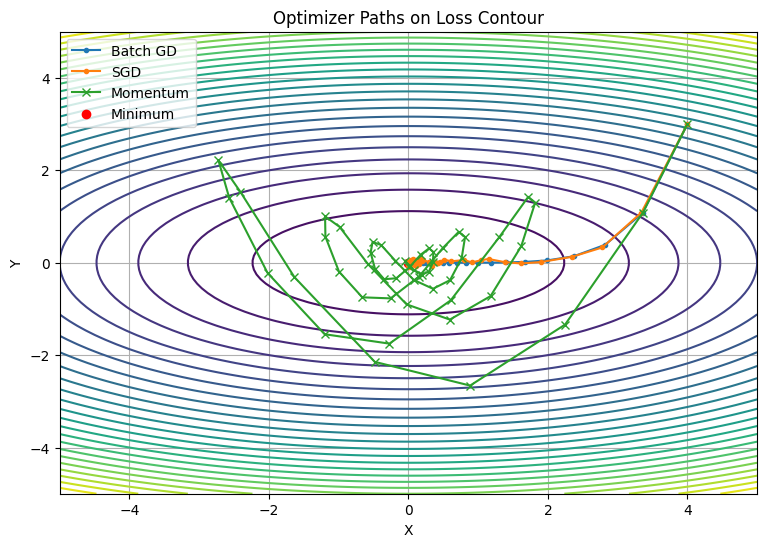


PART 4: Keras Optimizer Comparison

Optimizer: SGD
Test MSE: 0.0239
Test MAE: 0.1222
Training Time: 9.15 seconds

Optimizer: SGD + Momentum
Test MSE: 0.0206
Test MAE: 0.1128
Training Time: 7.97 seconds

Optimizer: Adam
Test MSE: 0.0197
Test MAE: 0.1149
Training Time: 9.73 seconds


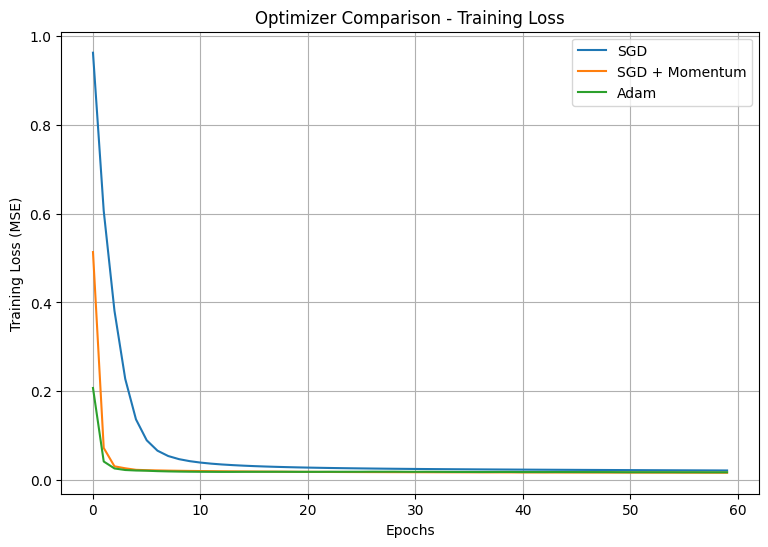

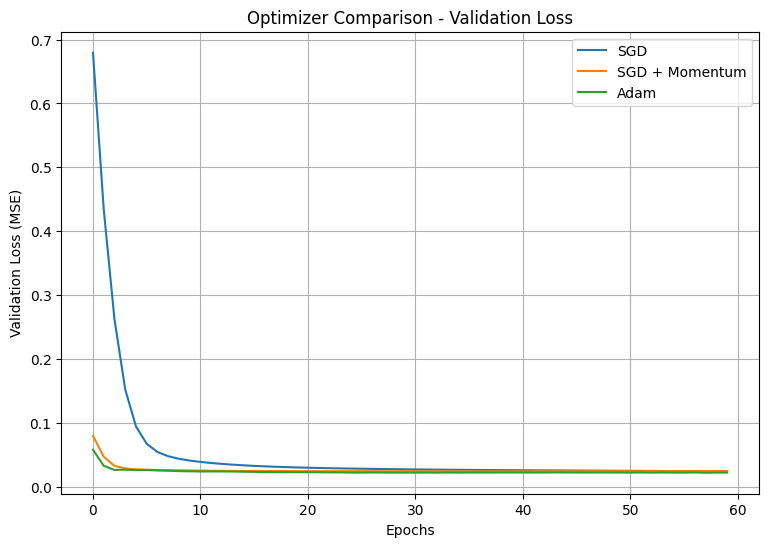


PART 6: Learning Rate Comparison

Learning Rate: 0.0001
Final Training Loss: 1.02517
Final Validation Loss: 1.10443

Learning Rate: 0.01
Final Training Loss: 0.0253
Final Validation Loss: 0.02738

Learning Rate: 1.0
Final Training Loss: nan
Final Validation Loss: nan


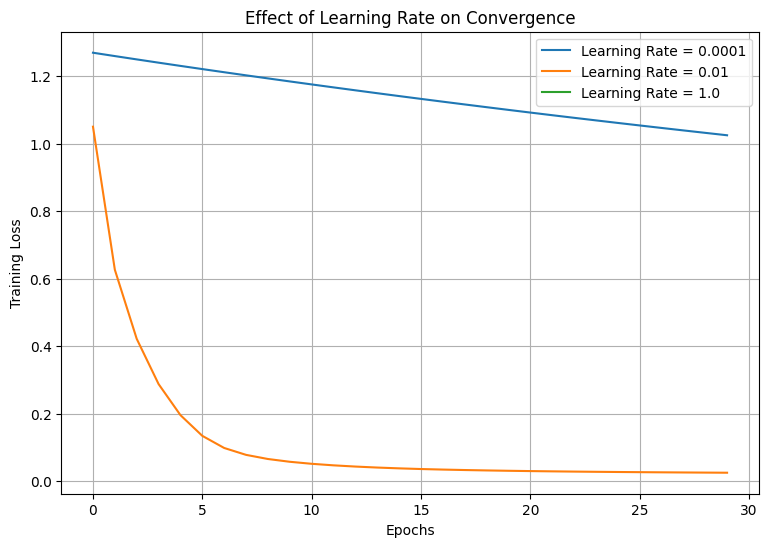


Experiment 6 Completed Successfully!


In [1]:

import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
import time

# Reproducibility
np.random.seed(42)
tf.random.set_seed(42)


# --------------------------------------------------
# PART 1: Implement optimizers from scratch
# --------------------------------------------------

# Loss function: f(x, y) = x^2 + 4y^2
def loss_function(x, y):
    return x**2 + 4 * y**2


# Gradient of the loss function
def gradient(x, y):
    return np.array([2 * x, 8 * y])


# Batch Gradient Descent
def batch_gd(start, learning_rate, iterations):
    point = np.array(start, dtype=float)
    path = [point.copy()]

    for i in range(iterations):
        grad = gradient(point[0], point[1])
        point = point - learning_rate * grad
        path.append(point.copy())

    return np.array(path)


# Stochastic Gradient Descent
def sgd(start, learning_rate, iterations):
    point = np.array(start, dtype=float)
    path = [point.copy()]

    for i in range(iterations):
        # Add random noise to simulate a sample gradient
        grad = gradient(point[0], point[1])
        noise = np.random.normal(0, 0.5, 2)

        point = point - learning_rate * (grad + noise)
        path.append(point.copy())

    return np.array(path)


# Momentum Gradient Descent
def momentum_gd(start, learning_rate, iterations, beta=0.9):
    point = np.array(start, dtype=float)
    velocity = np.zeros(2)
    path = [point.copy()]

    for i in range(iterations):
        grad = gradient(point[0], point[1])

        velocity = beta * velocity + learning_rate * grad
        point = point - velocity

        path.append(point.copy())

    return np.array(path)


# Run optimizers
start = [4, 3]
learning_rate = 0.08
iterations = 50

path_batch = batch_gd(start, learning_rate, iterations)
path_sgd = sgd(start, learning_rate, iterations)
path_momentum = momentum_gd(start, learning_rate, iterations)

print("PART 1: Optimizer Results")

for name, path in [
    ("Batch GD", path_batch),
    ("SGD", path_sgd),
    ("Momentum", path_momentum)
]:
    final_point = path[-1]
    final_loss = loss_function(final_point[0], final_point[1])

    print("\n", name)
    print("Final X:", round(final_point[0], 4))
    print("Final Y:", round(final_point[1], 4))
    print("Final Loss:", round(final_loss, 6))


# --------------------------------------------------
# PART 2: Plot optimizer paths on loss contour
# --------------------------------------------------

x = np.linspace(-5, 5, 100)
y = np.linspace(-5, 5, 100)

X, Y = np.meshgrid(x, y)
Z = loss_function(X, Y)

plt.figure(figsize=(9, 6))

plt.contour(X, Y, Z, levels=30)
plt.plot(path_batch[:, 0], path_batch[:, 1],
         marker="o", markersize=3, label="Batch GD")
plt.plot(path_sgd[:, 0], path_sgd[:, 1],
         marker=".", label="SGD")
plt.plot(path_momentum[:, 0], path_momentum[:, 1],
         marker="x", label="Momentum")

plt.scatter(0, 0, color="red", label="Minimum")

plt.xlabel("X")
plt.ylabel("Y")
plt.title("Optimizer Paths on Loss Contour")
plt.legend()
plt.grid(True)
plt.show()


# --------------------------------------------------
# PART 3: Generate delivery-time dataset
# --------------------------------------------------

# Features:
# Distance, Traffic Index, Weight, Time of Day

number_of_samples = 1000

distance = np.random.uniform(1, 50, number_of_samples)
traffic = np.random.uniform(1, 10, number_of_samples)
weight = np.random.uniform(1, 30, number_of_samples)
time_of_day = np.random.uniform(0, 24, number_of_samples)

# Combine input features
X_data = np.column_stack((
    distance, traffic, weight, time_of_day
))

# Delivery time target
y_data = (
    10
    + 1.5 * distance
    + 2.0 * traffic
    + 0.3 * weight
    + 0.5 * np.abs(time_of_day - 12)
    + np.random.normal(0, 3, number_of_samples)
)

y_data = y_data.reshape(-1, 1)

# Normalize input and output data
X_mean = X_data.mean(axis=0)
X_std = X_data.std(axis=0)

y_mean = y_data.mean()
y_std = y_data.std()

X_data = (X_data - X_mean) / X_std
y_data = (y_data - y_mean) / y_std

# Train and test split
split = int(0.8 * number_of_samples)

X_train = X_data[:split]
X_test = X_data[split:]

y_train = y_data[:split]
y_test = y_data[split:]


# --------------------------------------------------
# PART 4: Build and train Keras regression models
# --------------------------------------------------

def create_model():
    model = tf.keras.Sequential([
        tf.keras.layers.Input(shape=(4,)),
        tf.keras.layers.Dense(32, activation="relu"),
        tf.keras.layers.Dense(16, activation="relu"),
        tf.keras.layers.Dense(1)
    ])

    return model


optimizers = {
    "SGD": tf.keras.optimizers.SGD(learning_rate=0.01),

    "SGD + Momentum": tf.keras.optimizers.SGD(
        learning_rate=0.01,
        momentum=0.9
    ),

    "Adam": tf.keras.optimizers.Adam(
        learning_rate=0.01
    )
}

histories = {}
results = {}

print("\nPART 4: Keras Optimizer Comparison")

for name, optimizer in optimizers.items():

    model = create_model()

    model.compile(
        optimizer=optimizer,
        loss="mse",
        metrics=["mae"]
    )

    start_time = time.time()

    history = model.fit(
        X_train,
        y_train,
        epochs=60,
        batch_size=32,
        validation_split=0.2,
        verbose=0
    )

    training_time = time.time() - start_time

    test_loss, test_mae = model.evaluate(
        X_test, y_test, verbose=0
    )

    histories[name] = history

    results[name] = {
        "Test MSE": test_loss,
        "Test MAE": test_mae,
        "Training Time": training_time
    }

    print("\nOptimizer:", name)
    print("Test MSE:", round(test_loss, 4))
    print("Test MAE:", round(test_mae, 4))
    print("Training Time:", round(training_time, 2), "seconds")


# --------------------------------------------------
# PART 5: Plot loss against epochs
# --------------------------------------------------

plt.figure(figsize=(9, 6))

for name, history in histories.items():
    plt.plot(
        history.history["loss"],
        label=name
    )

plt.xlabel("Epochs")
plt.ylabel("Training Loss (MSE)")
plt.title("Optimizer Comparison - Training Loss")
plt.legend()
plt.grid(True)
plt.show()


# Plot validation loss
plt.figure(figsize=(9, 6))

for name, history in histories.items():
    plt.plot(
        history.history["val_loss"],
        label=name
    )

plt.xlabel("Epochs")
plt.ylabel("Validation Loss (MSE)")
plt.title("Optimizer Comparison - Validation Loss")
plt.legend()
plt.grid(True)
plt.show()


# --------------------------------------------------
# PART 6: Learning rate experimentation
# --------------------------------------------------

learning_rates = [0.0001, 0.01, 1.0]

lr_results = {}

print("\nPART 6: Learning Rate Comparison")

for lr in learning_rates:

    model = create_model()

    model.compile(
        optimizer=tf.keras.optimizers.SGD(
            learning_rate=lr
        ),
        loss="mse"
    )

    history = model.fit(
        X_train,
        y_train,
        epochs=30,
        batch_size=32,
        validation_data=(X_test, y_test),
        verbose=0
    )

    final_loss = history.history["loss"][-1]
    final_val_loss = history.history["val_loss"][-1]

    lr_results[lr] = history

    print("\nLearning Rate:", lr)
    print("Final Training Loss:", round(final_loss, 5))
    print("Final Validation Loss:", round(final_val_loss, 5))


# Plot learning rate comparison
plt.figure(figsize=(9, 6))

for lr, history in lr_results.items():
    plt.plot(
        history.history["loss"],
        label=f"Learning Rate = {lr}"
    )

plt.xlabel("Epochs")
plt.ylabel("Training Loss")
plt.title("Effect of Learning Rate on Convergence")
plt.legend()
plt.grid(True)
plt.show()


print("\nExperiment 6 Completed Successfully!")
